# Predicción de hipoglucemia asociada al ejercicio en personas con diabetes

**Proyecto de Aprendizaje Automático — revisión metodológica de la segunda entrega.**

**Pregunta:** ¿La glucosa media y la actividad física (MET medio) observadas durante 60 minutos permiten anticipar el inicio de un episodio de hipoglucemia de al menos 15 minutos durante los siguientes 60 minutos?

**Fuente:** CGMacros (*A Scientific Dataset for Personalized Nutrition and Diet Monitoring*). Los archivos de trabajo se encuentran en `data/`. Los resultados describen asociaciones, no causalidad ni recomendaciones clínicas individuales.

**Definiciones:** glucosa <70 mg/dL; episodio válido = al menos 15 mediciones consecutivas por minuto bajo 70 mg/dL (intervalo entre primera y última medición de 14 minutos). METs del archivo Fitbit se dividen por 10, como en el análisis original. Se emplea HbA1c >6,4 % como criterio operativo de selección; por sí sola no demuestra un diagnóstico clínico individual.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, balanced_accuracy_score, roc_auc_score

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data'/'bio.csv').is_file() and (p/'data'/'CGMacros_14_CSV_GitHub').is_dir()), None)
if raiz is None:
    raise FileNotFoundError('Descargá el repositorio completo y ejecutá desde su raíz o desde notebooks/. Deben existir data/bio.csv y data/CGMacros_14_CSV_GitHub/.')
carpeta = raiz/'data'/'CGMacros_14_CSV_GitHub'
bio = pd.read_csv(raiz/'data'/'bio.csv')
seleccion = bio.loc[bio['A1c PDL (Lab)'] > 6.4, 'subject'].astype(int).tolist()
print('Participantes seleccionados por HbA1c:', len(seleccion), seleccion)
assert len(seleccion)==14, 'Revisar la selección de participantes: no coincide con los 14 esperados.' 

Participantes seleccionados por HbA1c: 14 [3, 5, 12, 14, 28, 30, 35, 36, 38, 39, 42, 46, 47, 49]


## 1. Control de calidad y disponibilidad de variables

Se revisan por **cada uno de los 14 participantes** la cantidad de filas, fechas inválidas, duplicados temporales, faltantes y existencia de las variables necesarias. Los duplicados se eliminan conservando la primera medición y los registros se ordenan cronológicamente. No se interpola ni se utiliza información posterior para calcular predictores.

In [2]:
datos = {}
auditoria = []
for pid in seleccion:
    nombre = f'CGMacros-{pid:03d}'
    archivo = carpeta/f'{nombre}.csv'
    if not archivo.is_file():
        raise FileNotFoundError(f'No está {archivo}')
    df = pd.read_csv(archivo)
    filas_originales = len(df)
    if not {'Timestamp','Libre GL'}.issubset(df.columns):
        raise ValueError(f'Faltan Timestamp o Libre GL en {nombre}')
    df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
    invalidas = int(df['Timestamp'].isna().sum())
    df = df.dropna(subset=['Timestamp']).sort_values('Timestamp')
    duplicados = int(df['Timestamp'].duplicated().sum())
    df = df.drop_duplicates('Timestamp', keep='first').reset_index(drop=True)
    tiene_met = 'METs' in df.columns
    auditoria.append({'Participante':nombre,'Filas originales':filas_originales,'Fechas inválidas':invalidas,'Duplicados':duplicados,'Faltantes glucosa':int(df['Libre GL'].isna().sum()),'Tiene METs':tiene_met,'Faltantes METs':int(df['METs'].isna().sum()) if tiene_met else np.nan,'Filas tras limpieza':len(df)})
    if tiene_met:
        datos[nombre] = df
calidad = pd.DataFrame(auditoria)
print(calidad.to_string(index=False))
print('Total de registros originales:',calidad['Filas originales'].sum())
print('Participantes sin METs:',calidad.loc[~calidad['Tiene METs'],'Participante'].tolist())
print('Participantes con ambas variables:',len(datos))

Participante  Filas originales  Fechas inválidas  Duplicados  Faltantes glucosa  Tiene METs  Faltantes METs  Filas tras limpieza
CGMacros-003             14565                 0           0                  0        True             0.0                14565
CGMacros-005             14460                 0           0                  0        True            22.0                14460
CGMacros-012             14655                 0           0                  0        True             0.0                14655
CGMacros-014             17250                 0           0                  0        True          1951.0                17250
CGMacros-028             18735                 0           0                  0        True          3379.0                18735
CGMacros-030             15465                 0           0                  0        True          1632.0                15465
CGMacros-035             14400                 0           0                  0       False      

## 2. Construcción prospectiva de ventanas

Para **no seleccionar casos positivos a partir del inicio ya conocido del episodio**, se crean ventanas fijas, no solapadas, de 120 registros por participante, comenzando desde su primer registro. La primera hora es observación y la segunda es el horizonte de predicción. Solo se usan glucosa y METs de la primera hora como predictores.

- **Positivo (1):** observación sin hipoglucemia y comienzo de al menos un episodio válido de 15 registros consecutivos bajo 70 durante la hora futura; el episodio debe poder confirmarse dentro de esa hora.
- **Negativo (0):** observación sin hipoglucemia y ninguna lectura bajo 70 durante la hora futura.
- **Indeterminado:** aparece alguna lectura bajo 70 en el futuro, pero no se confirma un episodio válido completo; se excluye **de ambas clases**, con recuento explícito.

Se descartan ventanas con interrupciones temporales o faltantes en cualquiera de las dos horas, y aquellas con hipoglucemia ya presente en la observación. Se exige información futura completa únicamente para construir la etiqueta retrospectivamente; nunca se utiliza para los predictores. El muestreo fijo puede omitir episodios que caen entre ventanas y constituye una limitación del estudio.

In [3]:
filas=[]
controles=[]
for nombre,df in datos.items():
    n_total=n_validas=n_sin_cont=n_falt=n_hipo_pre=n_indet=0
    positivos=negativos=0
    for inicio in range(0,len(df)-119,120):
        n_total+=1
        w=df.iloc[inicio:inicio+120]
        if not w['Timestamp'].diff().iloc[1:].eq(pd.Timedelta(minutes=1)).all():
            n_sin_cont+=1; continue
        if w[['Libre GL','METs']].isna().any().any():
            n_falt+=1; continue
        obs=w.iloc[:60]; futuro=w.iloc[60:]
        if (obs['Libre GL']<70).any():
            n_hipo_pre+=1;continue
        bajos=futuro['Libre GL'].lt(70).to_numpy()
        inicios=np.flatnonzero(bajos & ~np.r_[False,bajos[:-1]])
        episodio_valido=any(i+15<=60 and bajos[i:i+15].all() for i in inicios)
        if episodio_valido:
            etiqueta=1; positivos+=1
        elif not bajos.any():
            etiqueta=0; negativos+=1
        else:
            n_indet+=1;continue
        filas.append({'Participante':nombre,'Inicio_observacion':obs['Timestamp'].iloc[0], 'Fin_observacion':obs['Timestamp'].iloc[-1], 'Inicio_prediccion':futuro['Timestamp'].iloc[0], 'Fin_prediccion':futuro['Timestamp'].iloc[-1], 'Glucosa_media':obs['Libre GL'].mean(), 'MET_medio':obs['METs'].mean()/10, 'Hipoglucemia':etiqueta})
    controles.append({'Participante':nombre,'Ventanas candidatas':n_total,'Sin continuidad':n_sin_cont,'Con faltantes':n_falt,'Hipoglucemia previa':n_hipo_pre,'Futuro indeterminado':n_indet,'Positivas':positivos,'Negativas':negativos})
control=pd.DataFrame(controles)
ventanas=pd.DataFrame(filas)
print(control.to_string(index=False))
print('TOTALES:',control.select_dtypes(include='number').sum().to_string())
print('Distribución de etiquetas:',ventanas.Hipoglucemia.value_counts().to_dict())
print('Participantes con positivos:',ventanas.loc[ventanas.Hipoglucemia.eq(1),'Participante'].nunique())
assert not ventanas.empty and ventanas.Hipoglucemia.nunique()==2
assert ventanas[['Glucosa_media','MET_medio']].notna().all().all()

Participante  Ventanas candidatas  Sin continuidad  Con faltantes  Hipoglucemia previa  Futuro indeterminado  Positivas  Negativas
CGMacros-003                  121                1              0                    5                     0          1        114
CGMacros-005                  120                0              0                    3                     0          2        115
CGMacros-012                  122                1              0                    0                     0          0        121
CGMacros-014                  143                0             16                    1                     1          0        125
CGMacros-028                  156                0             29                    2                     0          1        124
CGMacros-030                  128                0             13                    1                     0          0        114
CGMacros-036                  142                0             15                  

## 3. Exploración descriptiva

Cada fila es una ventana de un participante, **no un paciente independiente**. Las medias siguientes describen la muestra de ventanas y no prueban que el ejercicio cause hipoglucemia.

             Glucosa_media                 MET_medio             
                     count    mean  median     count  mean median
Hipoglucemia                                                     
0                     1201  133.41  122.40      1201  1.77   1.44
1                       12   95.51   86.96        12  1.59   1.32


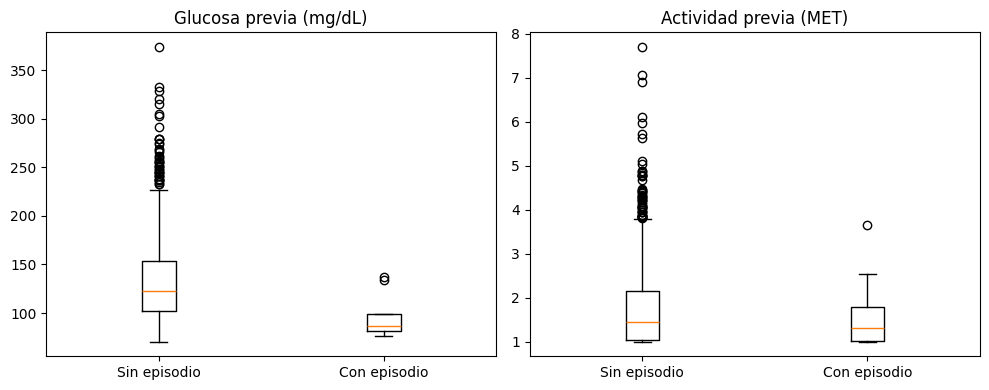

In [4]:
print(ventanas.groupby('Hipoglucemia')[['Glucosa_media','MET_medio']].agg(['count','mean','median']).round(2).to_string())
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,var,titulo in zip(axs,['Glucosa_media','MET_medio'],['Glucosa previa (mg/dL)','Actividad previa (MET)']):
    grupos=[ventanas.loc[ventanas.Hipoglucemia.eq(i),var] for i in [0,1]]
    ax.boxplot(grupos,tick_labels=['Sin episodio','Con episodio']);ax.set_title(titulo)
plt.tight_layout();plt.show()

## 4. Entrenamiento y prueba por participante

Se busca una separación reproducible de participantes que deje al menos un caso positivo y negativo en cada conjunto. **Nunca** se mezclan ventanas de la misma persona entre entrenamiento y prueba. Para evitar una evaluación artificialmente optimista, se reconoce que elegir la partición en función de las etiquetas es una limitación; no se selecciona según el rendimiento del modelo. El submuestreo de negativos y el ajuste del escalador se hacen **solo en entrenamiento**. La prueba conserva su prevalencia original.

In [5]:
opciones=[]
for semilla in range(100):
    gss=GroupShuffleSplit(n_splits=1,test_size=.3,random_state=semilla)
    it,iv=next(gss.split(ventanas,groups=ventanas.Participante))
    a,b=ventanas.iloc[it],ventanas.iloc[iv]
    if a.Hipoglucemia.sum()>=3 and b.Hipoglucemia.sum()>=3:
        opciones.append((semilla,it,iv));break
if not opciones:
    raise ValueError('No es posible formar conjuntos con al menos tres positivos por grupo.')
semilla,it,iv=opciones[0]
train=ventanas.iloc[it].copy();test=ventanas.iloc[iv].copy()
assert set(train.Participante).isdisjoint(test.Participante)
print('Semilla de separación:',semilla)
print('Participantes de entrenamiento:',sorted(train.Participante.unique()))
print('Participantes de prueba:',sorted(test.Participante.unique()))
print('Clases entrenamiento:',train.Hipoglucemia.value_counts().to_dict())
print('Clases prueba:',test.Hipoglucemia.value_counts().to_dict())
pos=train[train.Hipoglucemia.eq(1)]
neg=train[train.Hipoglucemia.eq(0)].sample(n=len(pos),random_state=42)
train_balanceado=pd.concat([pos,neg],ignore_index=True).sample(frac=1,random_state=42)
variables=['Glucosa_media','MET_medio']
scaler=StandardScaler()
X_train=scaler.fit_transform(train_balanceado[variables]);X_test=scaler.transform(test[variables])
y_train=train_balanceado.Hipoglucemia;y_test=test.Hipoglucemia
modelo=LogisticRegression(max_iter=1000,random_state=42)
modelo.fit(X_train,y_train)
print('Entrenamiento balanceado:',y_train.value_counts().to_dict())

Semilla de separación: 1
Participantes de entrenamiento: ['CGMacros-003', 'CGMacros-005', 'CGMacros-014', 'CGMacros-028', 'CGMacros-030', 'CGMacros-039', 'CGMacros-047']
Participantes de prueba: ['CGMacros-012', 'CGMacros-036', 'CGMacros-049']
Clases entrenamiento: {0: 861, 1: 6}
Clases prueba: {0: 340, 1: 6}
Entrenamiento balanceado: {0: 6, 1: 6}


## 5. Evaluación en participantes no vistos

La exactitud debe interpretarse junto con sensibilidad, precisión, falsos positivos y prevalencia de la clase positiva. El tamaño reducido de casos positivos limita la precisión de las estimaciones y su generalización.

In [6]:
pred_train=modelo.predict(X_train)
pred_test=modelo.predict(X_test)
proba=modelo.predict_proba(X_test)[:,1]
tn,fp,fn,tp=confusion_matrix(y_test,pred_test,labels=[0,1]).ravel()
print('Exactitud entrenamiento balanceado:',round(accuracy_score(y_train,pred_train),3))
print('Exactitud prueba:',round(accuracy_score(y_test,pred_test),3))
print('Exactitud balanceada prueba:',round(balanced_accuracy_score(y_test,pred_test),3))
print('ROC-AUC prueba:',round(roc_auc_score(y_test,proba),3))
print('Matriz de confusión [[VN, FP],[FN, VP]]:',[[int(tn),int(fp)],[int(fn),int(tp)]])
print(classification_report(y_test,pred_test,zero_division=0))
print('Coeficientes estandarizados:',dict(zip(variables,modelo.coef_[0].round(3))))

Exactitud entrenamiento balanceado: 0.75
Exactitud prueba: 0.699
Exactitud balanceada prueba: 0.683
ROC-AUC prueba: 0.731
Matriz de confusión [[VN, FP],[FN, VP]]: [[238, 102], [2, 4]]
              precision    recall  f1-score   support

           0       0.99      0.70      0.82       340
           1       0.04      0.67      0.07         6

    accuracy                           0.70       346
   macro avg       0.51      0.68      0.45       346
weighted avg       0.98      0.70      0.81       346

Coeficientes estandarizados: {'Glucosa_media': np.float64(-0.726), 'MET_medio': np.float64(-0.503)}


## 6. Conclusión y limitaciones

La conclusión cuantitativa se construye **a partir de las salidas calculadas**, no de números escritos de una ejecución anterior. La evaluación corresponde a ventanas de participantes no utilizados para entrenar; no constituye validación clínica ni permite inferir causalidad. Cuatro de los 14 participantes carecen de METs y no pueden aportar ventanas a un modelo con ambas variables. Las ventanas con faltantes, discontinuidades, hipoglucemia previa o eventos breves indeterminados se contabilizan y excluyen. El muestreo fijo no solapado reduce dependencia entre ventanas pero puede perder episodios. El número de participantes y episodios positivos es pequeño.

In [7]:
n_pos=int(ventanas.Hipoglucemia.sum());n_neg=int((ventanas.Hipoglucemia==0).sum())
print(f'Se construyeron {len(ventanas)} ventanas etiquetadas ({n_pos} positivas y {n_neg} negativas), de {ventanas.Participante.nunique()} participantes con variables completas.')
print(f'En prueba: {len(test)} ventanas de {test.Participante.nunique()} participantes; {int(y_test.sum())} positivas.')
print(f'La exactitud en prueba fue {accuracy_score(y_test,pred_test):.1%}; sensibilidad {tp/(tp+fn):.1%}; precisión {tp/(tp+fp):.1%}.' if (tp+fn)>0 and (tp+fp)>0 else 'No es posible estimar alguna métrica por ausencia de casos predichos o reales.')
print(f'Se identificaron {fp} falsos positivos y {fn} falsos negativos en prueba.')
print('Los resultados no establecen umbrales clínicos seguros ni demuestran que la actividad física cause hipoglucemia.')

Se construyeron 1213 ventanas etiquetadas (12 positivas y 1201 negativas), de 10 participantes con variables completas.
En prueba: 346 ventanas de 3 participantes; 6 positivas.
La exactitud en prueba fue 69.9%; sensibilidad 66.7%; precisión 3.8%.
Se identificaron 102 falsos positivos y 2 falsos negativos en prueba.
Los resultados no establecen umbrales clínicos seguros ni demuestran que la actividad física cause hipoglucemia.


## Cómo reproducir

1. Descargar el repositorio completo de GitHub (Code → Download ZIP) y descomprimirlo conservando `data/` y `notebooks/`.
2. Abrir `notebooks/hipoglucemia_ejercicio.ipynb` en Jupyter Notebook o JupyterLab desde esa estructura.
3. Contar con `pandas`, `numpy`, `matplotlib` y `scikit-learn`.
4. Reiniciar el kernel y ejecutar todas las celdas en orden.

**Nota sobre la interpretación:** los 14 archivos de participantes representan mediciones repetidas; los registros no son observaciones clínicas independientes. La clasificación operativa por HbA1c y las definiciones de ventanas corresponden a este análisis, no a una validación externa.